This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [ ]:
!pip install keras keras-hub --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.29.0 which is incompatible.


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

### Text-to-image models

In [ ]:
import keras
from keras import layers

In [ ]:
if keras.config.backend() == "torch":
    # The rest of this chapter will not do any training. The following keeps
    # PyTorch from using too much memory by disabling gradients. TensorFlow and
    # JAX use a much smaller memory footprint and do not need this hack.
    import torch

    torch.set_grad_enabled(False)

array([[[ 14, 110, 204],
        [  0, 102, 224],
        [  0, 101, 232],
        ...,
        [  0,  98, 231],
        [  0,  98, 222],
        [ 15, 103, 195]],

       [[  0,  98, 228],
        [  0,  98, 234],
        [  0,  97, 228],
        ...,
        [  0, 102, 227],
        [  0, 102, 233],
        [  8, 110, 224]],

       [[  0, 101, 231],
        [  0, 103, 228],
        [  0, 103, 230],
        ...,
        [  0, 104, 232],
        [  0, 107, 235],
        [  5, 112, 239]],

       ...,

       [[227,  60,   4],
        [224,  53,   8],
        [229,  55,   7],
        ...,
        [154, 216, 254],
        [154, 214, 254],
        [162, 223, 255]],

       [[215,  58,   8],
        [223,  53,   4],
        [229,  50,   6],
        ...,
        [154, 214, 254],
        [150, 214, 255],
        [143, 202, 248]],

       [[197,  73,  18],
        [219,  47,   6],
        [225,  46,   5],
        ...,
        [151, 212, 252],
        [148, 210, 254],
        [145, 189, 227]]], dtype=uint8)
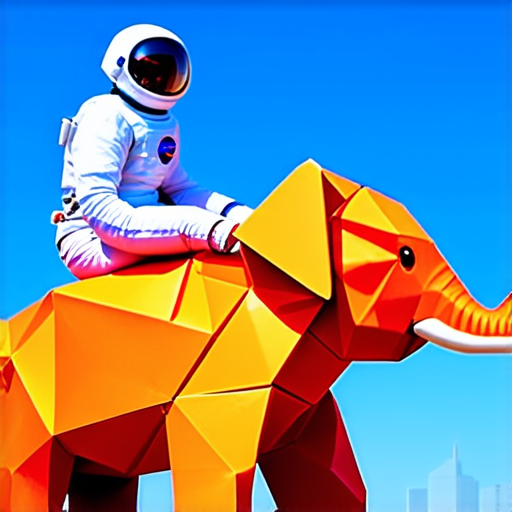

In [ ]:
import keras_hub

height, width = 512, 512
task = keras_hub.models.TextToImage.from_preset(
    "stable_diffusion_3_medium",
    image_shape=(height, width, 3),
    dtype="float16",
)
prompt = "A NASA astraunaut riding an origami elephant in New York City"
task.generate(prompt)

array([[[ 28,  33,  33],
        [ 15,  23,  23],
        [ 18,  20,  20],
        ...,
        [ 53,  57,  61],
        [108, 100,  93],
        [153, 144, 126]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [ 91,  94,  98],
        [130, 117, 127],
        [144, 135, 136]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [140, 143, 139],
        [134, 132, 127],
        [166, 157, 154]],

       ...,

       [[247, 139, 147],
        [244, 134, 142],
        [244, 137, 144],
        ...,
        [251, 220, 224],
        [247, 229, 234],
        [255, 241, 246]],

       [[239, 136, 143],
        [242, 131, 140],
        [241, 132, 139],
        ...,
        [236, 194, 204],
        [239, 203, 215],
        [246, 216, 223]],

       [[218, 142, 136],
        [235, 126, 139],
        [237, 126, 134],
        ...,
        [230, 180, 187],
        [228, 177, 183],
        [229, 197, 197]]], dtype=uint8)
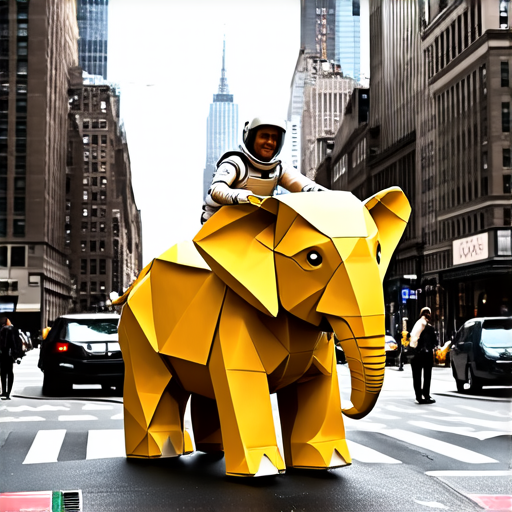

In [ ]:
task.generate(
    {
        "prompts": prompt,
        "negative_prompts": "blue color",
    }
)

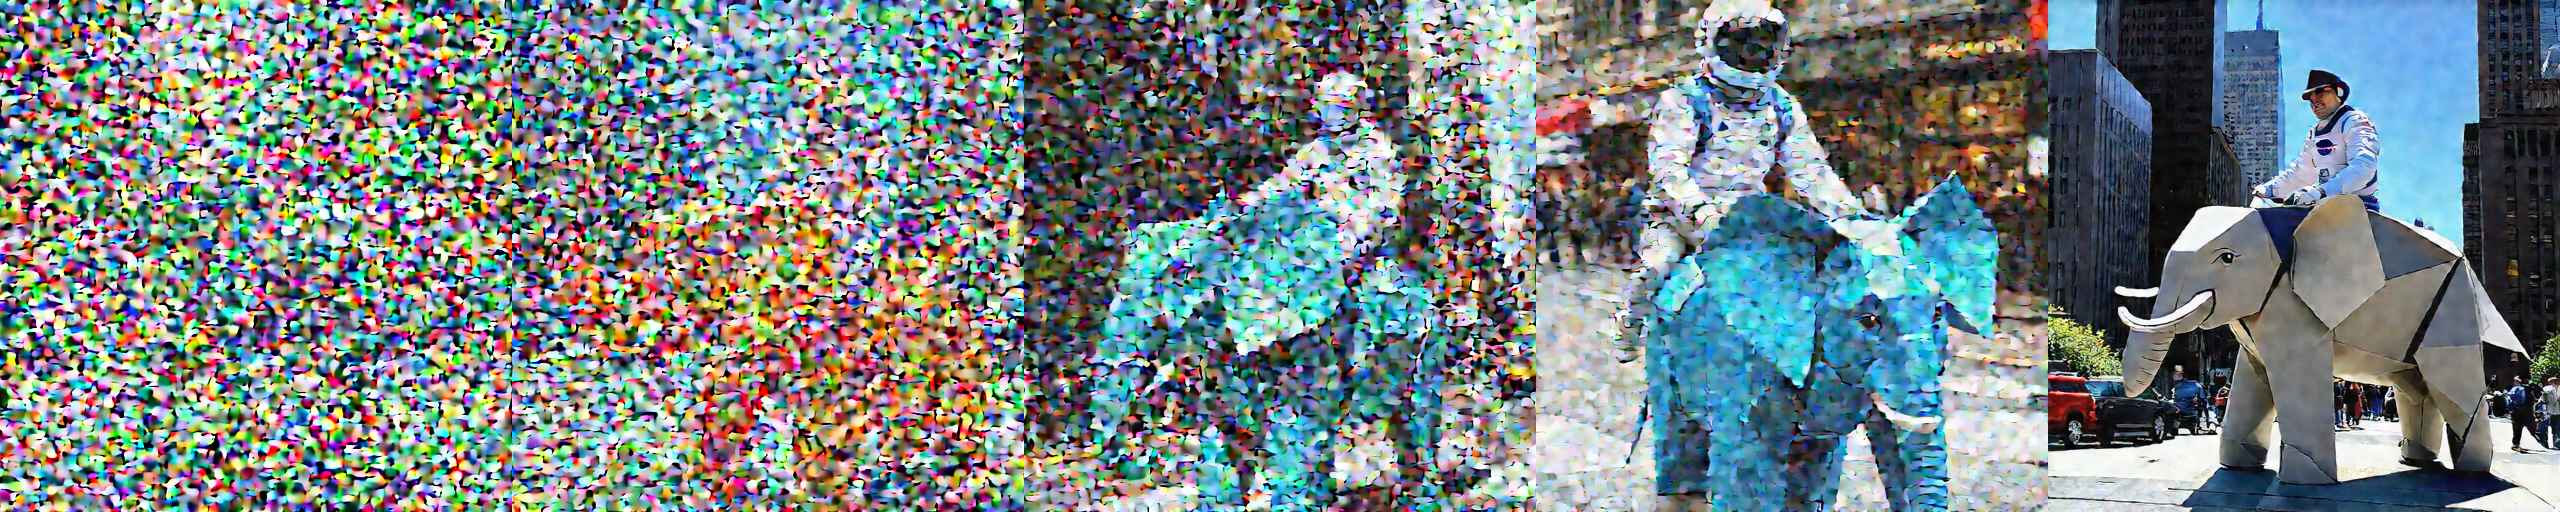

In [ ]:
import numpy as np
from PIL import Image

def display(images):
    return Image.fromarray(np.concatenate(images, axis=1))

display([task.generate(prompt, num_steps=x) for x in [5, 10, 15, 20, 25]])

#### Exploring the latent space of a text-to-image model

/tmp/ipykernel_4360/770988049.py:24: RuntimeWarning: invalid value encountered in cast
  return np.round(x * 255.0).astype("uint8")


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
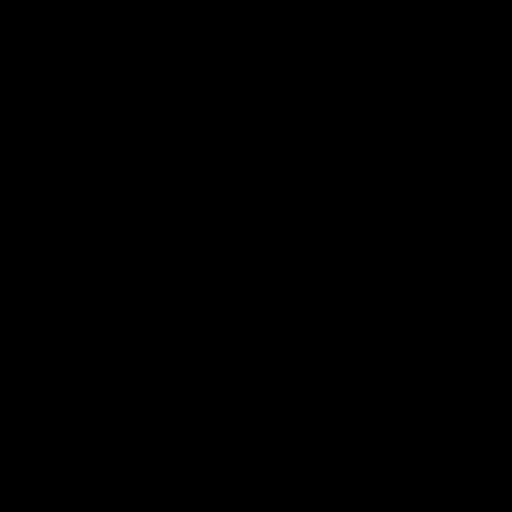

In [ ]:
from keras import random
from keras import ops
import numpy as np # Add numpy import for nan_to_num

def get_text_embeddings(prompt):
    token_ids = task.preprocessor.generate_preprocess([prompt])
    negative_token_ids = task.preprocessor.generate_preprocess(["blue color"])
    return task.backbone.encode_text_step(token_ids, negative_token_ids)

def denoise_with_text_embeddings(embeddings, num_steps=28, guidance_scale=7.0):
    latents = random.normal((1, height // 8, width // 8, 16))
    for step in range(num_steps):
        latents = task.backbone.denoise_step(
            latents,
            embeddings,
            step,
            num_steps,
            guidance_scale,
        )
    return task.backbone.decode_step(latents)[0]

def scale_output(x):
    x = ops.convert_to_numpy(x)
    x = np.nan_to_num(x) # Handle NaN values by converting them to 0
    x = np.clip((x + 1.0) / 2.0, 0.0, 1.0)
    return np.round(x * 255.0).astype("uint8")

embeddings = get_text_embeddings(prompt)
image = denoise_with_text_embeddings(embeddings)
scale_output(image)

In [ ]:
[x.shape for x in embeddings]

[(1, 154, 4096), (1, 154, 4096), (1, 2048), (1, 2048)]

In [ ]:
from keras import ops

def slerp(t, v1, v2):
    v1, v2 = ops.cast(v1, "float32"), ops.cast(v2, "float32")
    v1_norm = ops.linalg.norm(ops.ravel(v1))
    v2_norm = ops.linalg.norm(ops.ravel(v2))
    dot = ops.sum(v1 * v2 / (v1_norm * v2_norm))
    theta_0 = ops.arccos(dot)
    sin_theta_0 = ops.sin(theta_0)
    theta_t = theta_0 * t
    sin_theta_t = ops.sin(theta_t)
    s0 = ops.sin(theta_0 - theta_t) / sin_theta_0
    s1 = sin_theta_t / sin_theta_0
    return s0 * v1 + s1 * v2

def interpolate_text_embeddings(e1, e2, start=0, stop=1, num=10):
    embeddings = []
    for t in np.linspace(start, stop, num):
        embeddings.append(
            (
                slerp(t, e1[0], e2[0]),
                e1[1],
                slerp(t, e1[2], e2[2]),
                e1[3],
            )
        )
    return embeddings

In [ ]:
prompt1 = "A friendly dog looking up in a field of flowers"
prompt2 = "A horrifying, tentacled creature hovering over a field of flowers"
e1 = get_text_embeddings(prompt1)
e2 = get_text_embeddings(prompt2)

images = []
for et in interpolate_text_embeddings(e1, e2, start=0.5, stop=0.6, num=9):
    image = denoise_with_text_embeddings(et)
    images.append(scale_output(image))
display(images)